In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/config.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/tokenizer.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/metadata.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/model.weights.h5
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer/vocabulary.txt
/kaggle/input/competitions/nlp-getting-started/sample_submission.csv
/kaggle/input/competitions/nlp-getting-started/train.csv
/kaggle/input/competitions/nlp-getting-started/test.csv


In [5]:
import numpy as np
import pandas as pd
import tensorflow as tf

print(np.__version__, pd.__version__, tf.__version__)

2.1.3 2.3.3 2.20.0


In [6]:
import importlib.util
print(importlib.util.find_spec("keras_hub"))

ModuleSpec(name='keras_hub', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7c0a4a541cd0>, origin='/usr/local/lib/python3.13/dist-packages/keras_hub/__init__.py', submodule_search_locations=['/usr/local/lib/python3.13/dist-packages/keras_hub'])


In [4]:
%pip install "keras-hub==0.25.1" "tensorflow-text==2.20.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 15.0 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: keras-hub
    Found existing installation: keras-hub 0.26.0
    Uninstalling keras-hub-0.26.0:
      Successfully uninstalled keras-hub-0.26.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nlp 0.26.0 requires keras-hub==0.26.0, but you have keras-hub 0.25.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [7]:
import tensorflow as tf
import keras
import keras_hub

print(tf.__version__)
print(keras.__version__)
print(keras_hub.__version__)

2.20.0
3.13.2
0.26.0


In [8]:
classifier = keras_hub.models.DistilBertTextClassifier.from_preset(
    "distil_bert_base_en_uncased",
    num_classes=2,
)

classifier.summary()

I0000 00:00:1792677339.314463      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792677339.317866      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Preprocessor: "distil_bert_text_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/config.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/tokenizer.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/metadata.json
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/model.weights.h5
/kaggle/input/models/keras/distil_bert/keras/distil_bert_base_en_uncased/3/assets/tokenizer/vocabulary.txt
/kaggle/input/competitions/nlp-getting-started/sample_submission.csv
/kaggle/input/competitions/nlp-getting-started/train.csv
/kaggle/input/competitions/nlp-getting-started/test.csv


In [10]:
df_train = pd.read_csv("/kaggle/input/competitions/nlp-getting-started/train.csv")
df_test = pd.read_csv("/kaggle/input/competitions/nlp-getting-started/test.csv")

print('Training Set Shape = {}'.format(df_train.shape))
print('Training Set Memory Usage = {:.2f} MB'.format(df_train.memory_usage().sum() / 1024**2))
print('Test Set Shape = {}'.format(df_test.shape))
print('Test Set Memory Usage = {:.2f} MB'.format(df_test.memory_usage().sum() / 1024**2))

Training Set Shape = (7613, 5)
Training Set Memory Usage = 0.29 MB
Test Set Shape = (3263, 4)
Test Set Memory Usage = 0.10 MB


In [12]:
df_train.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [13]:
df_test.head()

,id,keyword,location,text
0,0,NaN,NaN,Just happened a terrible car crash
1,2,NaN,NaN,"Heard about #earthquake is different cities, s..."
2,3,NaN,NaN,"there is a forest fire at spot pond, geese are..."
3,9,NaN,NaN,Apocalypse lighting. #Spokane #wildfires
4,11,NaN,NaN,Typhoon Soudelor kills 28 in China and Taiwan


In [14]:
print("train")
print(df_train.isnull().sum())
print("test")
print(df_test.isnull().sum())

train
id             0
keyword       61
location    2533
text           0
target         0
dtype: int64
test
id             0
keyword       26
location    1105
text           0
dtype: int64


In [16]:
X = df_train["text"]
y = df_train["target"]

X_test = df_test["text"]

In [17]:
df_train["length"] = df_train["text"].apply(lambda x : len(x))
df_test["length"] = df_test["text"].apply(lambda x : len(x))

print("Train Length Stat")
print(df_train["length"].describe())
print()

print("Test Length Stat")
print(df_test["length"].describe())

Train Length Stat
count    7613.000000
mean      101.037436
std        33.781325
min         7.000000
25%        78.000000
50%       107.000000
75%       133.000000
max       157.000000
Name: length, dtype: float64

Test Length Stat
count    3263.000000
mean      102.108183
std        33.972158
min         5.000000
25%        78.000000
50%       109.000000
75%       134.000000
max       151.000000
Name: length, dtype: float64


Pre Process the Data


In [22]:
BATCH_SIZE = 32
NUM_TRAINING_EXAMPLES = df_train.shape[0]
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.2


EPOCHS = 3
AUTO = tf.data.experimental.AUTOTUNE

In [24]:
from sklearn.model_selection import train_test_split

X = df_train["text"]
y = df_train["target"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_test = df_test["text"]

EXPERIMENT 1

In [25]:
preset = "distil_bert_base_en_uncased"

# Step 1: Preprocessor
preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(
    preset,
    sequence_length=84
)

# Step 2: Pretrained classifier
classifier = keras_hub.models.DistilBertTextClassifier.from_preset(
    preset,
    preprocessor=preprocessor,
    num_classes=2
)

classifier.summary()

Preprocessor: "distil_bert_text_classifier_preprocessor_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item_1[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

****Train your own model, fine-tuning BERT

In [26]:
sample = preprocessor([
    "Massive earthquake hits California!"
])

print(sample["token_ids"])
print(sample["padding_mask"])

tf.Tensor(
[[ 101 5294 8372 4978 2662  999  102    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0    0    0    0    0    0    0    0    0]], shape=(1, 84), dtype=int32)
tf.Tensor(
[[ True  True  True  True  True  True  True False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False False
  False False False False False False False False False False False Fal

In [27]:
tokenizer = preprocessor.tokenizer

lengths = [
    len(tokenizer.tokenize(tweet))
    for tweet in df_train["text"]
]

import numpy as np

print("Median:", np.median(lengths))
print("95th percentile:", np.percentile(lengths, 95))
print("Maximum:", np.max(lengths))

Median: 31.0
95th percentile: 50.0
Maximum: 82


In [28]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [37]:
classifier.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), #'binary_crossentropy',
    optimizer=keras.optimizers.Adam(1e-5),
    metrics= ["accuracy"]  
)

# Fit
history = classifier.fit(x=X_train,
                         y=y_train,
                         batch_size=BATCH_SIZE,
                         epochs=EPOCHS, 
                         validation_data=(X_val, y_val)
                        )

Epoch 1/3
191/191 ━━━━━━━━━━━━━━━━━━━━ 106s 397ms/step - accuracy: 0.9268 - loss: 0.2147 - val_accuracy: 0.8129 - val_loss: 0.5360
Epoch 2/3
191/191 ━━━━━━━━━━━━━━━━━━━━ 57s 300ms/step - accuracy: 0.9373 - loss: 0.1816 - val_accuracy: 0.8011 - val_loss: 0.5628
Epoch 3/3
191/191 ━━━━━━━━━━━━━━━━━━━━ 55s 290ms/step - accuracy: 0.9484 - loss: 0.1556 - val_accuracy: 0.8070 - val_loss: 0.5873


In [30]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

predictions = classifier.predict(X_val.tolist())
y_pred = np.argmax(predictions, axis=1)

print(classification_report(y_val, y_pred))
print("F1:", f1_score(y_val, y_pred))
print(confusion_matrix(y_val, y_pred))

48/48 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step
              precision    recall  f1-score   support

           0       0.86      0.87      0.86       869
           1       0.82      0.80      0.81       654

    accuracy                           0.84      1523
   macro avg       0.84      0.84      0.84      1523
weighted avg       0.84      0.84      0.84      1523

F1: 0.8142414860681114
[[757 112]
 [128 526]]


In [33]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    f1_score
)
import numpy as np
import matplotlib.pyplot as plt

def displayConfusionMatrix(y_true, y_pred, dataset):
    predicted_labels = np.argmax(y_pred, axis=1)

    f1 = f1_score(y_true, predicted_labels)

    disp = ConfusionMatrixDisplay.from_predictions(
        y_true,
        predicted_labels,
        display_labels=["Not Disaster", "Disaster"],
        cmap=plt.cm.Blues
    )

    disp.ax_.set_title(
        f"{dataset} Dataset | F1 Score: {f1:.3f}"
    )

    plt.show()

48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step


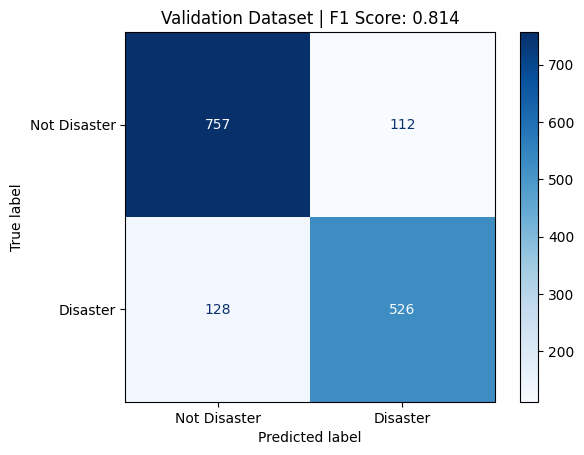

In [32]:
y_val_pred = classifier.predict(X_val.tolist())

displayConfusionMatrix(
    y_val,
    y_val_pred,
    "Validation"
)

In [34]:
from scipy.special import softmax

probs = softmax(predictions, axis=1)[:, 1]

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.3, 0.4, 0.5, 0.6]:
    pred = (probs >= threshold).astype(int)

    print(
        threshold,
        "Precision:", round(precision_score(y_val, pred), 3),
        "Recall:", round(recall_score(y_val, pred), 3),
        "F1:", round(f1_score(y_val, pred), 3)
    )

0.3 Precision: 0.765 Recall: 0.844 F1: 0.802
0.4 Precision: 0.791 Recall: 0.826 F1: 0.808
0.5 Precision: 0.824 Recall: 0.804 F1: 0.814
0.6 Precision: 0.845 Recall: 0.784 F1: 0.814


EXPERIMENT 2

In [39]:
preset = "distil_bert_base_en_uncased"

preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(
    preset,
    sequence_length=64
)

classifier = keras_hub.models.DistilBertTextClassifier.from_preset(
    preset,
    preprocessor=preprocessor,
    num_classes=2
)

In [40]:
= keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True
)

history = classifier.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5
191/191 ━━━━━━━━━━━━━━━━━━━━ 99s 356ms/step - loss: 0.4426 - sparse_categorical_accuracy: 0.8072 - val_loss: 0.3967 - val_sparse_categorical_accuracy: 0.8313
Epoch 2/5
191/191 ━━━━━━━━━━━━━━━━━━━━ 47s 243ms/step - loss: 0.3113 - sparse_categorical_accuracy: 0.8818 - val_loss: 0.5009 - val_sparse_categorical_accuracy: 0.8017


In [41]:
from sklearn.metrics import f1_score
import numpy as np

predictions_exp2 = classifier.predict(X_val.tolist())
y_pred_exp2 = np.argmax(predictions_exp2, axis=1)

print("Experiment 2 F1:", f1_score(y_val, y_pred_exp2))

48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 104ms/step
Experiment 2 F1: 0.8086373790022338


EXPERIMENT 3

In [42]:
import keras
import keras_hub

keras.utils.set_random_seed(42)

classifier = keras_hub.models.DistilBertTextClassifier.from_preset(
    "distil_bert_base_en_uncased",
    preprocessor=preprocessor,
    num_classes=2
)

In [45]:
classifier.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

In [46]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    min_delta=0.001,
    restore_best_weights=True
)

history = classifier.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5
191/191 ━━━━━━━━━━━━━━━━━━━━ 96s 346ms/step - accuracy: 0.7811 - loss: 0.4830 - val_accuracy: 0.8437 - val_loss: 0.3811
Epoch 2/5
191/191 ━━━━━━━━━━━━━━━━━━━━ 47s 245ms/step - accuracy: 0.8529 - loss: 0.3662 - val_accuracy: 0.8470 - val_loss: 0.3795
Epoch 3/5
191/191 ━━━━━━━━━━━━━━━━━━━━ 45s 236ms/step - accuracy: 0.8759 - loss: 0.3211 - val_accuracy: 0.8516 - val_loss: 0.3807
Epoch 4/5
191/191 ━━━━━━━━━━━━━━━━━━━━ 46s 238ms/step - accuracy: 0.9020 - loss: 0.2708 - val_accuracy: 0.8404 - val_loss: 0.4069


In [47]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

predictions_exp3 = classifier.predict(X_val.tolist())
y_pred_exp3 = np.argmax(predictions_exp3, axis=1)

print(classification_report(y_val, y_pred_exp3))
print("Experiment 3 F1:", f1_score(y_val, y_pred_exp3))

48/48 ━━━━━━━━━━━━━━━━━━━━ 7s 105ms/step
              precision    recall  f1-score   support

           0       0.85      0.89      0.87       869
           1       0.84      0.80      0.82       654

    accuracy                           0.85      1523
   macro avg       0.85      0.84      0.84      1523
weighted avg       0.85      0.85      0.85      1523

Experiment 3 F1: 0.816967792615868


In [50]:
errors = pd.DataFrame({
    "tweet": X_val.to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": y_pred_exp3
})

false_positives = errors[
    (errors.actual == 0) & (errors.predicted == 1)
]

false_negatives = errors[
    (errors.actual == 1) & (errors.predicted == 0)
]

print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))
pd.set_option('display.max_colwidth', None)


display(false_positives.head(10))
display(false_negatives.head(10))

False positives: 99
False negatives: 134


,tweet,actual,predicted
11,MEGALPOLIS Area Petting Party Shiver \nFear Instant .... GLOBAL Inundation OVERFLOW\nWAS Commencement WRITE ?? ?,0,1
14,if firefighters acted like cops they'd drive around shooting a flamethrower at burning buildings,0,1
34,@TroySlaby22 slicker than an oil spill,0,1
43,Has An Ancient Nuclear Reactor Been Discovered In Africa? ÛÒ Your... http://t.co/qadUfO8zXg,0,1
58,Article by Michael Jackman at Metro Times Detroit:\nThe group later downgraded the estimate to 37 square miles of... http://t.co/h31mmuduqt,0,1
68,That sounds about right. Our building will have a thunderstorm inside one day when the air masses collide. https://t.co/2rTQ9QmGPB,0,1
80,I hope it rains throughout the whole weekend I hope it floods and the portaloos become sentient.,0,1
86,#Sismo M 1.3 - 1km NNE of The Geysers California: Time2015-08-05 23:40:21 UTC2015-08-05 16:40:21 -07:00 a... http://t.co/x6el3ySYcn #CS,0,1
88,Drowning in Actavis suicide,0,1
158,Governor weighs parole for California school bus hijacker http://t.co/7NPBfRzEJL http://t.co/Y0kByy8nce,0,1


,tweet,actual,predicted
5,Hollywood Movie About Trapped Miners Released in Chile: 'The 33' Hollywood movie about trapped miners starring... http://t.co/tyyfG4qQvM,1,0
7,I can't drown my demons they know how to swim,1,0
16,'It looks like a mudslide' poor thing! ?? #greatbritishbakeoff,1,0
27,I agree with certain cultural appropriation things but honestly if u looked at my house it screams appropriation bc Buddhas and stuff-,1,0
29,The Dress Memes Have Officially Exploded On The Internet http://t.co/3drSmxw3cr,1,0
42,Newlyweds feed thousands of Syrian refugees instead of hosting a banquet wedding dinner - http://t.co/XZV0lT9ZZk via @smh,1,0
44,My prediction for the Vikings game this Sunday....dont expect a whole lot. Infact I think Zimmer goal is....injury free 1st game,1,0
59,#hot Funtenna: hijacking computers to send data as sound waves [Black Hat 2015] http://t.co/J2aQs5loxu #prebreak #best,1,0
81,@leedsrouge Love what you picked! We're playing WORTH IT by FIFTH HARM/KID INK because of you! Listen &amp; Vote: http://t.co/0wrATkA2jL,1,0
84,@PrablematicLA @Adweek I'm actually currently dressed for a snowstorm...despite being in the middle of a Texas summer. Thanks office A/C.,1,0


In [51]:
import numpy as np
import pandas as pd

test_predictions = classifier.predict(
    df_test["text"].tolist()
)

predicted_labels = np.argmax(test_predictions, axis=1)

102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step


In [52]:
predicted_labels

array([1, 1, 1, ..., 1, 1, 1])

In [69]:
submission = pd.DataFrame({
    "id": df_test["id"],
    "target": predicted_labels
})

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

display(submission.head())
print(submission.shape)

,id,target
0,0,1
1,2,1
2,3,1
3,9,1
4,11,1


(3263, 2)


## DistilBERT Fine-Tuning: Experiments and Analysis

### 1. Model Architecture and Preprocessing

We fine-tuned `distil_bert_base_en_uncased`, a pretrained transformer model, to classify tweets as disaster-related (1) or non-disaster-related (0).

**Preprocessing decisions:**
- Used the pretrained DistilBERT WordPiece tokenizer.
- Reduced sequence length from 160 to 64 tokens after analyzing token distributions (median: 31, 95th percentile: 50).
- Used an 80:20 training-validation split.
- Applied token padding and attention masking.
- Evaluated performance using accuracy, precision, recall, F1 and cross-entropy loss.

### 2. Fine-Tuning Experiments

We conducted three training experiments to investigate the effects of training duration, learning rate and EarlyStopping.

| Experiment | Configuration | Validation F1 |
|---|---|---|
| Experiment 1 | Initial fine-tuning, 3 epochs | 0.8142 |
| Experiment 2 | EarlyStopping, patience = 1 | 0.8086 |
| **Experiment 3** | **Learning rate = 1e-5, patience = 2** | **0.8170** |

**Observations:**

- Experiment 1 showed signs of overfitting after Epoch 2, as training accuracy increased while validation performance deteriorated.
- Experiment 2 demonstrated that EarlyStopping does not guarantee improved model performance.
- Experiment 3 achieved the highest validation F1 of 0.8170.
- In Experiment 3, Epoch 2 achieved the lowest validation loss, while Epoch 3 achieved the highest validation accuracy.
- EarlyStopping restored the weights associated with the lowest validation loss.

The results demonstrate the importance of checkpoint selection and evaluation on unseen data. Since Experiment 3 changed both learning rate and patience, the individual contribution of each change cannot be isolated.

### 3. Classification Threshold Optimization

We evaluated multiple disaster-classification thresholds to understand the trade-off between precision and recall.

| Threshold | Precision | Recall | F1 |
|---|---:|---:|---:|
| 0.3 | 0.765 | 0.844 | 0.802 |
| 0.4 | 0.791 | 0.826 | 0.808 |
| 0.5 | 0.824 | 0.804 | 0.814 |
| 0.6 | 0.845 | 0.784 | 0.814 |

*These threshold results were obtained from the earlier model, not Experiment 3.*

Lowering the threshold improved recall but increased false positives. Because Kaggle evaluates using F1, maximizing recall alone was not the objective.

### 4. Error Analysis of the Best Model

Experiment 3 produced:

| Error type | Count |
|---|---:|
| False positives | 99 |
| False negatives | 134 |

**Key error patterns:**

- **Figurative language:** Disaster-related vocabulary used metaphorically, such as references to fire or flooding.
- **Hypothetical situations:** Tweets describing imagined disasters rather than real events.
- **Ambiguous context:** References to disaster-related news, entertainment or historical incidents.
- **Potential label noise:** Some labelled examples did not clearly align with the definition of an actual disaster.

Error analysis suggests that even pretrained transformers struggle when classification requires external context, figurative-language interpretation or resolution of ambiguous labels.

### 5. DistilBERT Conclusion

Our best DistilBERT experiment achieved **validation F1 = 0.8170**, demonstrating that pretrained contextual representations can be effectively adapted to disaster-tweet classification.

Further improvements could include learning-rate scheduling, controlled layer-freezing experiments, additional text features and repeated evaluation across random seeds.

These results are based on a single validation split and should not be interpreted as guaranteed performance on unseen datasets.

In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    lowercase=True,
    stop_words=None
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(df_test["text"])

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)
print("Test:", X_test_tfidf.shape)

Training: (6090, 5000)
Validation: (1523, 5000)
Test: (3263, 5000)


In [54]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [55]:
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred_lr = lr_model.predict(X_val_tfidf)

print(classification_report(y_val, y_pred_lr))
print("TF-IDF F1:", f1_score(y_val, y_pred_lr))
print(confusion_matrix(y_val, y_pred_lr))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       869
           1       0.83      0.72      0.77       654

    accuracy                           0.82      1523
   macro avg       0.82      0.80      0.81      1523
weighted avg       0.82      0.82      0.81      1523

TF-IDF F1: 0.7698607698607699
[[772  97]
 [184 470]]


In [57]:
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)

In [58]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("lr", LogisticRegression(max_iter=1000))
])

param_grid = {
    "tfidf__max_features": [5000, 10000, 20000],
    "tfidf__ngram_range": [(1,1), (1,2)],
    "lr__C": [0.1, 1, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

y_pred_tuned = grid.predict(X_val)

print("Tuned validation F1:", f1_score(y_val, y_pred_tuned))

Best parameters: {'lr__C': 1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}
Best CV F1: 0.7441687912336126
Tuned validation F1: 0.7660961695191524


In [63]:
best_model = grid.best_estimator_

In [64]:
# Train on all 7,613 labelled tweets
best_model.fit(df_train["text"], df_train["target"])

# Predict on Kaggle's test dataset
test_predictions = best_model.predict(df_test["text"])

# Generate submission
submission = pd.DataFrame({
    "id": df_test["id"],
    "target": test_predictions
})

submission.to_csv(
    "/kaggle/working/submission_tfidf.csv",
    index=False
)

display(submission.head())

,id,target
0,0,1
1,2,0
2,3,1
3,9,0
4,11,1


In [59]:
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, classification_report

svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_val_tfidf)

print(classification_report(y_val, y_pred_svm))
print("SVM F1:", f1_score(y_val, y_pred_svm))

              precision    recall  f1-score   support

           0       0.81      0.85      0.83       869
           1       0.78      0.74      0.76       654

    accuracy                           0.80      1523
   macro avg       0.80      0.80      0.80      1523
weighted avg       0.80      0.80      0.80      1523

SVM F1: 0.763921568627451


In [61]:
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

svm_final = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("svm", LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=5000
    ))
])

# Train on all labelled tweets
svm_final.fit(df_train["text"], df_train["target"])

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                ('svm', LinearSVC(max_iter=5000, random_state=42))])

In [62]:
svm_preds = svm_final.predict(df_test["text"])

submission_svm = pd.DataFrame({
    "id": df_test["id"],
    "target": svm_preds
})

submission_svm.to_csv(
    "/kaggle/working/submission_svm.csv",
    index=False
)

display(submission_svm.head())

,id,target
0,0,1
1,2,1
2,3,1
3,9,1
4,11,1


In [67]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

models = {
    "DistilBERT": y_pred_exp3,
    "TF-IDF + Logistic Regression": y_pred_lr,
    "TF-IDF + Tuned Logistic Regression": y_pred_tuned,
    "TF-IDF + Linear SVM": y_pred_svm
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred)
    })

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(
    "F1", ascending=False
)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1
0,DistilBERT,0.8470,0.8401,0.7951,0.8170
1,TF-IDF + Logistic Regression,0.8155,0.8289,0.7187,0.7699
2,TF-IDF + Tuned Logistic Regression,0.8116,0.8202,0.7187,0.7661
3,TF-IDF + Linear SVM,0.8024,0.7842,0.7446,0.7639


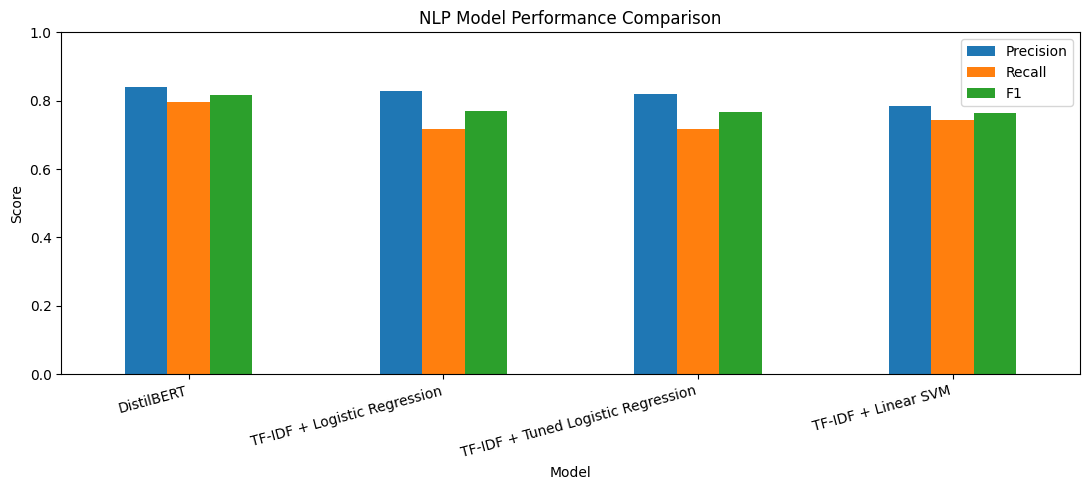

In [68]:

import matplotlib.pyplot as plt

comparison_df.set_index("Model")[
    ["Precision", "Recall", "F1"]
].plot(kind="bar", figsize=(11, 5))

plt.title("NLP Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


## Inference

This project compared transformer-based and traditional NLP approaches for classifying disaster-related tweets.

Fine-tuned **DistilBERT achieved the highest validation F1 score of 0.8170**, outperforming TF-IDF with Logistic Regression (0.7699) and Linear SVM (0.7639).

Fine-tuning experiments showed that learning rate, training duration and checkpoint selection influenced generalization. Error analysis highlighted challenges involving figurative language, ambiguous disaster-related terminology and potentially inconsistent labels.

While DistilBERT offered the strongest classification performance on the held-out validation set, traditional models provided computationally efficient baselines.

**Overall, the results demonstrate the value of pretrained contextual language representations for disaster-tweet classification**, while also highlighting the importance of careful evaluation and error analysis.

## Final Conclusions and Limitations

### Key Findings

This project compared four NLP modelling approaches for binary disaster-tweet classification.

- **DistilBERT achieved the highest validation F1 (0.8170)**, outperforming TF-IDF + Logistic Regression (0.7699) and Linear SVM (0.7639).
- Hyperparameter tuning using GridSearchCV did not improve Logistic Regression's held-out validation F1.
- DistilBERT demonstrated better recall for disaster-related tweets, suggesting that pretrained contextual representations were beneficial.
- Error analysis identified figurative language, ambiguous contexts and potentially inconsistent labels as important challenges.

### Limitations

1. **Single validation split:** Results were evaluated using one 80:20 train-validation split. Performance may vary with different random seeds or data partitions.
2. **Limited hyperparameter exploration:** Only a small selection of training configurations and traditional ML parameters was tested.
3. **Potential label noise:** Some tweets appeared inconsistently labelled, making reliable classification more difficult.
4. **No repeated experiments:** We did not perform repeated training runs to estimate the variability of model performance.

### Future Improvements

- Evaluate models across multiple random seeds or cross-validation folds.
- Experiment with transformer layer freezing and learning-rate scheduling.
- Investigate the contribution of keyword and location information.
- Compare computational efficiency and inference time across models.

### Final Takeaway

**Fine-tuned DistilBERT was the strongest model on the held-out validation set**, outperforming traditional TF-IDF-based classifiers. However, the simpler models offer lower computational cost and remain useful baselines.

These findings are specific to this dataset and experimental setup.